# 9. Algoritmos genéticos

Los algoritmos genéticos (*genetic algorithms*) son el primer método poblacional del libro. En lugar de mejorar una sola solución, mantienen una población de soluciones y generan otras nuevas combinando las mejores, con operadores inspirados en la selección natural y la herencia genética. El capítulo presenta el esquema general y lo aplica a la mochila con codificación binaria. Con ese ejemplo compara las maneras de manejar las soluciones infactibles, de seleccionar a los padres y de formar la población siguiente. Después lleva el método a las permutaciones del agente viajero y de las reinas y termina con una comparación con los métodos de trayectoria de los capítulos 4 a 6.

In [1]:
import math
import random
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

## Instancias y código común

El capítulo usa la mochila de 100 objetos, las reinas de $30 \times 30$ y el agente viajero de 50 ciudades. La celda oculta repite el código de los capítulos 4 a 6 que se usa en la comparación final, es decir, las clases de los problemas, la búsqueda local, ILS, la búsqueda tabú, los vecindarios y la GVNS.

In [2]:
np.random.seed(42)
random.seed(42)

# Mismas instancias de los capítulos 1, 3 y 4
N_OBJETOS = 20
pesos20 = np.random.randint(1, 31, size=N_OBJETOS)
valores20 = np.random.randint(1, 51, size=N_OBJETOS)
capacidad20 = int(0.4 * pesos20.sum())

N_CIUDADES = 50
ciudades = np.random.uniform(0, 100, size=(N_CIUDADES, 2))
distancias = np.sqrt(((ciudades[:, None, :] - ciudades[None, :, :]) ** 2).sum(axis=2))

# Mochila de 100 objetos con valores correlacionados con los pesos
rng = np.random.default_rng(2026)
pesos100 = rng.integers(1, 101, size=100)
valores100 = pesos100 + 10
capacidad100 = int(0.5 * pesos100.sum())


def optimo_mochila_pd(pesos, valores, capacidad):
    """Valor óptimo de la mochila 0-1 por programación dinámica sobre la capacidad."""
    mejor = np.zeros(capacidad + 1, dtype=np.int64)
    for w, v in zip(pesos, valores):
        mejor[w:] = np.maximum(mejor[w:], mejor[:-w] + v) if w > 0 else mejor[w:]
    return int(mejor[capacidad])


OPTIMO_MOCHILA100 = optimo_mochila_pd(pesos100, valores100, capacidad100)
print(f"Mochila de 100 objetos: peso total {pesos100.sum()}, capacidad {capacidad100}, "
      f"valor óptimo por programación dinámica {OPTIMO_MOCHILA100}")
print(f"Comprobación con la mochila de 20 objetos: {optimo_mochila_pd(pesos20, valores20, capacidad20)} (capítulo 1: 402)")

Mochila de 100 objetos: peso total 5028, capacidad 2514, valor óptimo por programación dinámica 3204
Comprobación con la mochila de 20 objetos: 402 (capítulo 1: 402)


In [3]:
class Mochila:
    """Mochila 0-1. Costo: valor con signo cambiado. Movimientos: flip e intercambio."""

    def __init__(self, pesos, valores, capacidad):
        self.pesos, self.valores, self.capacidad = pesos, valores, capacidad
        self.n = len(pesos)

    def aleatoria(self):
        x = np.zeros(self.n, dtype=int)
        peso = 0
        for i in np.random.permutation(self.n):
            if np.random.random() < 0.5 and peso + self.pesos[i] <= self.capacidad:
                x[i] = 1
                peso += self.pesos[i]
        return x

    def costo(self, x):
        return -int(np.dot(x, self.valores))

    def movimientos(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        movs = [('flip', i) for i in range(self.n)] + [('swap', i, j) for i in dentro for j in fuera]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        r = random.randrange(self.n + len(dentro) * len(fuera))
        if r < self.n:
            return ('flip', r)
        r -= self.n
        return ('swap', dentro[r // len(fuera)], fuera[r % len(fuera)])

    def delta(self, x, mov):
        peso = np.dot(x, self.pesos)
        if mov[0] == 'flip':
            i = mov[1]
            signo = 1 if x[i] == 0 else -1
            if peso + signo * self.pesos[i] > self.capacidad:
                return None
            return -signo * self.valores[i]
        _, i, j = mov
        if peso - self.pesos[i] + self.pesos[j] > self.capacidad:
            return None
        return self.valores[i] - self.valores[j]

    def aplicar(self, x, mov):
        y = x.copy()
        if mov[0] == 'flip':
            y[mov[1]] = 1 - y[mov[1]]
        else:
            y[mov[1]], y[mov[2]] = 0, 1
        return y

    def perturbar(self, x, k=3):
        y = x.copy()
        for i in np.random.choice(self.n, size=k, replace=False):
            y[i] = 1 - y[i]
        while np.dot(y, self.pesos) > self.capacidad:
            y[np.random.choice(np.flatnonzero(y == 1))] = 0
        return y

    def construir_grasp(self, alfa):
        x = np.zeros(self.n, dtype=int)
        peso = 0
        while True:
            candidatos = [i for i in range(self.n) if x[i] == 0 and peso + self.pesos[i] <= self.capacidad]
            if not candidatos:
                return x
            razon = {i: self.valores[i] / self.pesos[i] for i in candidatos}
            r_max, r_min = max(razon.values()), min(razon.values())
            lrc = [i for i in candidatos if razon[i] >= r_max - alfa * (r_max - r_min)]
            i = random.choice(lrc)
            x[i] = 1
            peso += self.pesos[i]

    # Atributos tabú: los objetos que cambian de estado
    def atributos(self, x, mov):
        return {mov[1]} if mov[0] == 'flip' else {mov[1], mov[2]}

    def es_tabu(self, x, mov, tabu_hasta, iteracion):
        return any(tabu_hasta.get(a, 0) > iteracion for a in self.atributos(x, mov))


class Reinas:
    """n reinas sobre permutaciones. Costo: pares en conflicto. Movimiento: intercambio de dos filas."""

    def __init__(self, n):
        self.n = n

    def aleatoria(self):
        return list(np.random.permutation(self.n))

    def costo(self, s):
        diag1 = Counter(i - f for i, f in enumerate(s))
        diag2 = Counter(i + f for i, f in enumerate(s))
        return sum(c * (c - 1) // 2 for c in diag1.values()) + sum(c * (c - 1) // 2 for c in diag2.values())

    def movimientos(self, s):
        movs = [(i, j) for i in range(self.n - 1) for j in range(i + 1, self.n)]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, s):
        return tuple(sorted(random.sample(range(self.n), 2)))

    def _ataques(self, s, col, fila, excluir):
        """Reinas que atacan en diagonal a una reina en (col, fila), sin contar las columnas excluidas."""
        return sum(1 for c, f in enumerate(s) if c not in excluir and abs(f - fila) == abs(c - col))

    def delta(self, s, mov):
        """Cambio en los conflictos calculado solo con las dos reinas que se mueven."""
        i, j = mov
        antes = (self._ataques(s, i, s[i], (i, j)) + self._ataques(s, j, s[j], (i, j))
                 + (abs(s[i] - s[j]) == j - i))
        despues = (self._ataques(s, i, s[j], (i, j)) + self._ataques(s, j, s[i], (i, j))
                   + (abs(s[j] - s[i]) == j - i))
        return despues - antes

    def aplicar(self, s, mov):
        t = list(s)
        i, j = mov
        t[i], t[j] = t[j], t[i]
        return t

    def perturbar(self, s, k=3):
        t = list(s)
        for _ in range(k):
            i, j = random.sample(range(self.n), 2)
            t[i], t[j] = t[j], t[i]
        return t

    def construir_grasp(self, alfa):
        s, libres = [], set(range(self.n))
        for col in range(self.n):
            ataques = {f: sum(1 for c, g in enumerate(s) if abs(g - f) == col - c) for f in libres}
            a_min, a_max = min(ataques.values()), max(ataques.values())
            lrc = [f for f in libres if ataques[f] <= a_min + alfa * (a_max - a_min)]
            f = random.choice(lrc)
            s.append(f)
            libres.remove(f)
        return s

    # Atributos tabú: la fila que deja cada reina que se mueve (no puede volver a ella)
    def atributos(self, s, mov):
        i, j = mov
        return {(i, s[i]), (j, s[j])}

    def es_tabu(self, s, mov, tabu_hasta, iteracion):
        i, j = mov
        return tabu_hasta.get((i, s[j]), 0) > iteracion or tabu_hasta.get((j, s[i]), 0) > iteracion


class Viajero:
    """Agente viajero. Costo: longitud del recorrido. Movimiento: 2-opt."""

    def __init__(self, distancias):
        self.d = distancias
        self.n = len(distancias)

    def aleatoria(self):
        return list(np.random.permutation(self.n))

    def costo(self, ruta):
        return sum(self.d[ruta[k], ruta[(k + 1) % self.n]] for k in range(self.n))

    def movimientos(self, ruta):
        movs = [(i, j) for i in range(self.n - 1) for j in range(i + 2, self.n) if not (i == 0 and j == self.n - 1)]
        random.shuffle(movs)
        return movs

    def movimiento_aleatorio(self, ruta):
        while True:
            i, j = sorted(random.sample(range(self.n), 2))
            if j >= i + 2 and not (i == 0 and j == self.n - 1):
                return (i, j)

    def delta(self, ruta, mov):
        i, j = mov
        a, b, c, d = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % self.n]
        return self.d[a, c] + self.d[b, d] - self.d[a, b] - self.d[c, d]

    def aplicar(self, ruta, mov):
        i, j = mov
        return ruta[:i + 1] + ruta[i + 1:j + 1][::-1] + ruta[j + 1:]

    def perturbar(self, ruta, k=None):
        p1, p2, p3 = sorted(random.sample(range(1, self.n), 3))
        return ruta[:p1] + ruta[p2:p3] + ruta[p1:p2] + ruta[p3:]

    def construir_grasp(self, alfa):
        ruta = [random.randrange(self.n)]
        pendientes = set(range(self.n)) - {ruta[0]}
        while pendientes:
            dist = {j: self.d[ruta[-1], j] for j in pendientes}
            d_min, d_max = min(dist.values()), max(dist.values())
            lrc = [j for j in pendientes if dist[j] <= d_min + alfa * (d_max - d_min)]
            j = random.choice(lrc)
            ruta.append(j)
            pendientes.remove(j)
        return ruta

    # Atributos tabú: los arcos que el movimiento quita (no se pueden volver a poner)
    def atributos(self, ruta, mov):
        i, j = mov
        a, b, c, d = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % self.n]
        return {frozenset((a, b)), frozenset((c, d))}

    def es_tabu(self, ruta, mov, tabu_hasta, iteracion):
        i, j = mov
        a, b, c, d = ruta[i], ruta[i + 1], ruta[j], ruta[(j + 1) % self.n]
        agregados = (frozenset((a, c)), frozenset((b, d)))
        return any(tabu_hasta.get(arco, 0) > iteracion for arco in agregados)


class Presupuesto:
    """Cuenta las evaluaciones de vecinos y avisa cuando se agotan."""

    def __init__(self, maximo):
        self.maximo, self.usadas = maximo, 0

    def gastar(self, k=1):
        self.usadas += k

    @property
    def agotado(self):
        return self.usadas >= self.maximo


def busqueda_local(prob, x, presupuesto):
    """Primera mejora, como en el capítulo 4."""
    c = prob.costo(x)
    while not presupuesto.agotado:
        mejoro = False
        for mov in prob.movimientos(x):
            if presupuesto.agotado:
                break
            d = prob.delta(x, mov)
            presupuesto.gastar()
            if d is not None and d < -1e-9:
                x, c = prob.aplicar(x, mov), c + d
                mejoro = True
                break
        if not mejoro:
            break
    return x, c


def busqueda_local_iterada(prob, presupuesto):
    """ILS del capítulo 4."""
    x, c = busqueda_local(prob, prob.aleatoria(), presupuesto)
    mejor_x, mejor_c = x, c
    while not presupuesto.agotado:
        y, cy = busqueda_local(prob, prob.perturbar(x), presupuesto)
        if cy <= c:
            x, c = y, cy
            if c < mejor_c:
                mejor_x, mejor_c = x, c
    return mejor_x, mejor_c


def grasp(prob, presupuesto, alfa=0.3):
    """GRASP del capítulo 4."""
    mejor_x, mejor_c = None, math.inf
    while not presupuesto.agotado:
        x0 = prob.construir_grasp(alfa)
        presupuesto.gastar()
        x, c = busqueda_local(prob, x0, presupuesto)
        if c < mejor_c:
            mejor_x, mejor_c = x, c
    return mejor_x, mejor_c


def busqueda_tabu(prob, presupuesto, permanencia, muestra=None, x0=None):
    """
    En cada iteración evalúa los vecinos de la solución actual (todos, o una muestra
    aleatoria de tamaño muestra) y se mueve al mejor que no sea tabú, aunque empeore.
    Un movimiento tabú se admite si produce una solución mejor que la mejor encontrada
    (criterio de aspiración). Los atributos del movimiento aplicado quedan prohibidos
    durante permanencia iteraciones.
    """
    x = prob.aleatoria() if x0 is None else x0
    c = prob.costo(x)
    mejor_x, mejor_c = x, c
    tabu_hasta = {}
    iteracion = 0
    historia = []
    while not presupuesto.agotado:
        iteracion += 1
        if muestra is None:
            candidatos = prob.movimientos(x)
        else:
            candidatos = [prob.movimiento_aleatorio(x) for _ in range(muestra)]
        mejor_mov, mejor_d = None, math.inf
        for mov in candidatos:
            if presupuesto.agotado:
                break
            d = prob.delta(x, mov)
            presupuesto.gastar()
            if d is None:
                continue
            if prob.es_tabu(x, mov, tabu_hasta, iteracion) and not (c + d < mejor_c - 1e-9):
                continue  # Tabú y sin aspiración
            if d < mejor_d:
                mejor_mov, mejor_d = mov, d
        if mejor_mov is None:
            continue
        for a in prob.atributos(x, mejor_mov):
            tabu_hasta[a] = iteracion + permanencia
        x, c = prob.aplicar(x, mejor_mov), c + mejor_d
        if c < mejor_c - 1e-9:
            mejor_x, mejor_c = x, c
        historia.append((c, mejor_c))
    return mejor_x, mejor_c, historia


class Flip:
    """Mochila, N1: cambia el estado de un objeto."""
    nombre = 'flip'

    def __init__(self, prob):
        self.p = prob

    def movimientos(self, x):
        movs = list(range(self.p.n))
        random.shuffle(movs)
        return movs

    def delta(self, x, i):
        return self.p.delta(x, ('flip', i))

    def aplicar(self, x, i):
        return self.p.aplicar(x, ('flip', i))


class Intercambio:
    """Mochila, N2: saca un objeto y mete otro."""
    nombre = 'intercambio 1-1'

    def __init__(self, prob):
        self.p = prob

    def movimientos(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        movs = [(i, j) for i in dentro for j in fuera]
        random.shuffle(movs)
        return movs

    def delta(self, x, mov):
        return self.p.delta(x, ('swap', mov[0], mov[1]))

    def aplicar(self, x, mov):
        return self.p.aplicar(x, ('swap', mov[0], mov[1]))


class Intercambio12:
    """Mochila, N3: saca un objeto y mete dos."""
    nombre = 'intercambio 1-2'

    def __init__(self, prob):
        self.p = prob

    def movimientos(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        movs = [(i, j, k) for i in dentro for a, j in enumerate(fuera) for k in fuera[a + 1:]]
        random.shuffle(movs)
        return movs

    def delta(self, x, mov):
        i, j, k = mov
        p = self.p
        if np.dot(x, p.pesos) - p.pesos[i] + p.pesos[j] + p.pesos[k] > p.capacidad:
            return None
        return p.valores[i] - p.valores[j] - p.valores[k]

    def aplicar(self, x, mov):
        i, j, k = mov
        y = x.copy()
        y[i], y[j], y[k] = 0, 1, 1
        return y


class Intercambio22:
    """Mochila, N4: saca dos objetos y mete otros dos."""
    nombre = 'intercambio 2-2'

    def __init__(self, prob):
        self.p = prob

    def movimientos(self, x):
        dentro, fuera = np.flatnonzero(x == 1), np.flatnonzero(x == 0)
        movs = [(i, h, j, k) for a, i in enumerate(dentro) for h in dentro[a + 1:]
                for b, j in enumerate(fuera) for k in fuera[b + 1:]]
        random.shuffle(movs)
        return movs

    def delta(self, x, mov):
        i, h, j, k = mov
        p = self.p
        if np.dot(x, p.pesos) - p.pesos[i] - p.pesos[h] + p.pesos[j] + p.pesos[k] > p.capacidad:
            return None
        return p.valores[i] + p.valores[h] - p.valores[j] - p.valores[k]

    def aplicar(self, x, mov):
        i, h, j, k = mov
        y = x.copy()
        y[i], y[h], y[j], y[k] = 0, 0, 1, 1
        return y


class DosOpt:
    """Agente viajero, N1: 2-opt."""
    nombre = '2-opt'

    def __init__(self, prob):
        self.p = prob

    def movimientos(self, ruta):
        return self.p.movimientos(ruta)

    def delta(self, ruta, mov):
        return self.p.delta(ruta, mov)

    def aplicar(self, ruta, mov):
        return self.p.aplicar(ruta, mov)


class OrOpt:
    """Agente viajero, N2: or-opt. Mueve un tramo de 1, 2 o 3 ciudades consecutivas a otra posición."""
    nombre = 'or-opt'

    def __init__(self, prob, largos=(1, 2, 3)):
        self.p = prob
        self.largos = largos

    def movimientos(self, ruta):
        n = self.p.n
        movs = []
        for L in self.largos:
            for i in range(n - L + 1):  # El tramo ocupa las posiciones i, ..., i + L - 1
                fuera = set(range(i - 1, i + L))  # Posiciones tras las que no tiene sentido insertar
                movs += [(i, L, q) for q in range(n) if q not in fuera and not (i == 0 and q == n - 1)]
        random.shuffle(movs)
        return movs

    def delta(self, ruta, mov):
        i, L, q = mov
        n, d = self.p.n, self.p.d
        a, s0, sL, b = ruta[i - 1], ruta[i], ruta[i + L - 1], ruta[(i + L) % n]
        c, e = ruta[q], ruta[(q + 1) % n]
        return d[a, b] + d[c, s0] + d[sL, e] - d[a, s0] - d[sL, b] - d[c, e]

    def aplicar(self, ruta, mov):
        i, L, q = mov
        tramo = ruta[i:i + L]
        resto = ruta[:i] + ruta[i + L:]
        pos = resto.index(ruta[q])
        return resto[:pos + 1] + tramo + resto[pos + 1:]


def vnd(vecindarios, prob, x, presupuesto):
    """
    Descenso por vecindad variable con cambio de vecindad secuencial y primera mejora.
    En el vecindario k busca el primer vecino que mejora la solución; si lo encuentra,
    se mueve a él y vuelve al primer vecindario; si no, pasa al siguiente.
    Termina cuando ningún vecindario mejora la solución.
    """
    c = prob.costo(x)
    k = 0
    while k < len(vecindarios) and not presupuesto.agotado:
        vec = vecindarios[k]
        mejoro = False
        for mov in vec.movimientos(x):
            if presupuesto.agotado:
                break
            d = vec.delta(x, mov)
            presupuesto.gastar()
            if d is not None and d < -1e-9:
                x, c = vec.aplicar(x, mov), c + d
                mejoro = True
                break
        k = 0 if mejoro else k + 1
    return x, c


def agitar_mochila(prob, x, k):
    """Agitación en la vecindad k de la mochila: k cambios de estado al azar y reparación."""
    return prob.perturbar(x, k)


def agitar_viajero(prob, ruta, k):
    """Agitación en la vecindad k del viajero: k movimientos 2-opt al azar."""
    for _ in range(k):
        ruta = prob.aplicar(ruta, prob.movimiento_aleatorio(ruta))
    return ruta


def vns(prob, presupuesto, agitar, busqueda, k_max, x0=None):
    """
    VNS con cambio de vecindad secuencial. Agita la solución actual en la vecindad k,
    aplica la búsqueda (local o VND) y, si el resultado mejora la solución actual,
    se mueve a él y vuelve a k = 1; si no, pasa a k + 1. Después de k_max vuelve a 1.
    """
    x = prob.aleatoria() if x0 is None else x0
    x, c = busqueda(x, presupuesto)
    historia = [(presupuesto.usadas, c)]
    k = 1
    while not presupuesto.agotado:
        y, cy = busqueda(agitar(prob, x, k), presupuesto)
        if cy < c - 1e-9:
            x, c, k = y, cy, 1
        else:
            k = k + 1 if k < k_max else 1
        historia.append((presupuesto.usadas, c))
    return x, c, historia


def vns_basica(prob, presupuesto, agitar, k_max=5):
    """VNS básica: la búsqueda es la búsqueda local de primera mejora del capítulo 4."""
    return vns(prob, presupuesto, agitar, lambda x, pres: busqueda_local(prob, x, pres), k_max)


def gvns(prob, presupuesto, agitar, vecindarios, k_max=5):
    """VNS general: la búsqueda es el VND con varios vecindarios."""
    return vns(prob, presupuesto, agitar, lambda x, pres: vnd(vecindarios, prob, x, pres), k_max)


mochila100 = Mochila(pesos100, valores100, capacidad100)
reinas = Reinas(30)
viajero = Viajero(distancias)

## El esquema de un algoritmo genético

Un algoritmo genético trabaja con una población de individuos, cada uno una solución codificada, y la renueva generación tras generación con cinco componentes:

- la inicialización genera la primera población, en este capítulo al azar;
- la evaluación calcula la aptitud (*fitness*) de cada individuo, que en un problema de maximización suele ser el valor de la función objetivo, ajustado si el individuo es infactible;
- la selección escoge los padres, de modo que los individuos con mayor aptitud tengan más probabilidad de reproducirse;
- el cruce (*crossover*) combina dos padres en dos hijos, con probabilidad $p_c$, y la mutación cambia al azar una parte pequeña de cada hijo;
- el reemplazo decide qué individuos forman la población siguiente.

La función `algoritmo_genetico` implementa este esquema para cualquier codificación que defina cómo generar un individuo al azar, cómo evaluarlo, cómo cruzar dos y cómo mutar uno. En cada generación produce tantos hijos como individuos tiene la población. Cada evaluación de un individuo gasta una unidad del presupuesto, de modo que el algoritmo se puede comparar con los métodos de trayectoria por el número de soluciones evaluadas. Al final devuelve el mejor individuo factible que encontró en toda la corrida.

La selección y el reemplazo tienen varias variantes, que las secciones siguientes comparan. La selección por torneo escoge dos individuos al azar y se queda con el de mayor aptitud. La selección por ruleta escoge un individuo con probabilidad proporcional a su aptitud, después de restarle a todas las aptitudes la menor de la población, para que sean positivas. En el reemplazo generacional, los hijos reemplazan a toda la población; con elitismo, el mejor individuo de la generación anterior reemplaza al peor hijo si es mejor que todos los hijos. En la competencia entre padres e hijos, cada lugar de la población siguiente lo gana el mejor de dos individuos escogidos al azar entre padres e hijos. El reemplazo por reglas de factibilidad, que se explica más adelante, enfrenta cada hijo con un padre.

In [4]:
class Individuo:
    """Una solución con su valor (a maximizar), su violación de las restricciones y su aptitud."""

    def __init__(self, x, valor, violacion, aptitud):
        self.x, self.valor, self.violacion, self.aptitud = x, valor, violacion, aptitud


def seleccion_torneo(poblacion, k=2):
    """Escoge k individuos al azar y devuelve el de mayor aptitud."""
    return max(random.sample(poblacion, k), key=lambda ind: ind.aptitud)


def seleccion_ruleta(poblacion):
    """Escoge un individuo con probabilidad proporcional a su aptitud, desplazada para que sea positiva."""
    aptitudes = np.array([ind.aptitud for ind in poblacion], dtype=float)
    pesos_sel = aptitudes - aptitudes.min() + 1e-9
    return poblacion[np.random.choice(len(poblacion), p=pesos_sel / pesos_sel.sum())]


def mejor_segun_restricciones(a, b):
    """Reglas de factibilidad: gana la factible; entre factibles, el de mayor valor; entre infactibles, el que viola menos."""
    if (a.violacion == 0) != (b.violacion == 0):
        return a if a.violacion == 0 else b
    if a.violacion == 0:
        return a if a.valor >= b.valor else b
    return a if a.violacion <= b.violacion else b


def algoritmo_genetico(cod, presupuesto, tam_poblacion=50, prob_cruce=0.9, seleccion='torneo',
                       reemplazo='generacional', elitismo=True, medir_diversidad=False):
    """
    Algoritmo genético generacional sobre una codificación cod, que define aleatoria,
    evaluar, cruce y mutacion. Cada evaluación de un individuo gasta una unidad del presupuesto.
    Devuelve el mejor individuo factible encontrado y la historia del mejor valor factible
    (y de la diversidad de la población, si medir_diversidad es verdadero).
    """
    def evaluar(x):
        presupuesto.gastar()
        return cod.evaluar(x)

    poblacion = [evaluar(cod.aleatoria()) for _ in range(tam_poblacion)]
    mejor = None
    historia = []

    def actualizar_mejor(individuos):
        nonlocal mejor
        for ind in individuos:
            if ind.violacion == 0 and (mejor is None or ind.valor > mejor.valor):
                mejor = ind

    actualizar_mejor(poblacion)
    while not presupuesto.agotado:
        # Selección de padres, cruce y mutación
        hijos = []
        while len(hijos) < tam_poblacion and not presupuesto.agotado:
            if seleccion == 'torneo':
                p1, p2 = seleccion_torneo(poblacion), seleccion_torneo(poblacion)
            else:
                p1, p2 = seleccion_ruleta(poblacion), seleccion_ruleta(poblacion)
            if random.random() < prob_cruce:
                h1, h2 = cod.cruce(p1.x, p2.x)
            else:
                h1, h2 = cod.copiar(p1.x), cod.copiar(p2.x)
            for h in (cod.mutacion(h1), cod.mutacion(h2)):
                if len(hijos) < tam_poblacion and not presupuesto.agotado:
                    hijos.append(evaluar(h))
        if len(hijos) < tam_poblacion:
            actualizar_mejor(hijos)
            break
        actualizar_mejor(hijos)

        # Reemplazo
        if reemplazo == 'generacional':
            nueva = hijos
            if elitismo:
                mejor_padre = max(poblacion, key=lambda ind: ind.aptitud)
                peor = min(range(len(nueva)), key=lambda i: nueva[i].aptitud)
                if mejor_padre.aptitud > max(ind.aptitud for ind in nueva):
                    nueva[peor] = mejor_padre
        elif reemplazo == 'competencia':
            union = poblacion + hijos
            nueva = [max(random.sample(union, 2), key=lambda ind: ind.aptitud) for _ in range(tam_poblacion)]
        else:  # 'restricciones': el hijo i compite con el padre i según las reglas de factibilidad
            nueva = [mejor_segun_restricciones(p, h) for p, h in zip(poblacion, hijos)]
        poblacion = nueva
        historia.append((presupuesto.usadas, mejor.valor if mejor else None,
                         cod.diversidad(poblacion) if medir_diversidad else None))
    return mejor, historia

## La mochila con codificación binaria

En la codificación binaria de la mochila, un individuo es el mismo vector $x \in \{0,1\}^n$ de los capítulos anteriores, que se interpreta como un cromosoma con un gen por objeto. La clase `MochilaBinaria` define los operadores:

- el cruce de un punto corta los dos padres en una posición al azar $k$ e intercambia las colas, de modo que los hijos son $(x_1, \dots, x_k, y_{k+1}, \dots, y_n)$ y $(y_1, \dots, y_k, x_{k+1}, \dots, x_n)$;
- el cruce uniforme decide al azar, gen por gen, de qué padre hereda el primer hijo, y el segundo hereda del otro padre;
- la mutación cambia cada gen con probabilidad $1/n$, de modo que en promedio cambia un gen por hijo.

El laboratorio del curso usa otra mutación, en la que cada hijo muta con cierta probabilidad y, si muta, cambia un solo gen. Los experimentos de esta sección usan, salvo que se diga otra cosa, cruce uniforme con probabilidad $p_c = 0{,}9$, selección por torneo, reemplazo generacional con elitismo, población de 50 individuos y 50 000 evaluaciones, con 5 semillas, y cambian un componente a la vez.

In [5]:
class MochilaBinaria:
    """Codificación binaria de la mochila, con penalización o con reparación de las soluciones infactibles."""

    def __init__(self, pesos, valores, capacidad, manejo='reparacion', lam=0.5, cruce='uniforme'):
        self.pesos, self.valores, self.capacidad = pesos, valores, capacidad
        self.n = len(pesos)
        self.manejo, self.lam, self.tipo_cruce = manejo, lam, cruce
        self.orden_razon = np.argsort(-valores / pesos)  # De mayor a menor razón valor/peso

    def aleatoria(self):
        return np.random.randint(0, 2, size=self.n)

    def copiar(self, x):
        return x.copy()

    def diversidad(self, poblacion):
        """Distancia de Hamming promedio entre pares de individuos, como fracción del número de genes."""
        X = np.array([ind.x for ind in poblacion])
        m = len(X)
        unos = X.sum(axis=0)
        return float((unos * (m - unos)).sum() / (m * (m - 1) / 2) / self.n)

    def reparar(self, x):
        """Saca objetos de menor razón valor/peso hasta que quepan y luego mete los de mayor razón que quepan."""
        x = x.copy()
        peso = int(np.dot(x, self.pesos))
        for i in self.orden_razon[::-1]:
            if peso <= self.capacidad:
                break
            if x[i]:
                x[i], peso = 0, peso - self.pesos[i]
        for i in self.orden_razon:
            if not x[i] and peso + self.pesos[i] <= self.capacidad:
                x[i], peso = 1, peso + self.pesos[i]
        return x

    def evaluar(self, x):
        if self.manejo == 'reparacion':
            x = self.reparar(x)
        valor = int(np.dot(x, self.valores))
        violacion = max(0, int(np.dot(x, self.pesos)) - self.capacidad)
        aptitud = valor if violacion == 0 else self.lam * valor - (1 - self.lam) * violacion
        return Individuo(x, valor, violacion, aptitud)

    def cruce(self, x, y):
        if self.tipo_cruce == 'un_punto':
            k = random.randrange(1, self.n)
            return np.concatenate([x[:k], y[k:]]), np.concatenate([y[:k], x[k:]])
        mascara = np.random.randint(0, 2, size=self.n).astype(bool)  # Uniforme
        return np.where(mascara, x, y), np.where(mascara, y, x)

    def mutacion(self, x):
        """Cambia cada gen con probabilidad 1/n."""
        cambia = np.random.random(self.n) < 1 / self.n
        return np.where(cambia, 1 - x, x)


def correr_ag(crear_cod, max_eval, semillas, **kw):
    """Corre el algoritmo genético con varias semillas y devuelve los mejores valores factibles."""
    valores_finales = []
    for semilla in semillas:
        random.seed(semilla)
        np.random.seed(semilla)
        mejor, _ = algoritmo_genetico(crear_cod(), Presupuesto(max_eval), **kw)
        valores_finales.append(mejor.valor if mejor else float('nan'))
    return valores_finales

### Penalización o reparación

Los cruces y la mutación producen selecciones que no caben en la mochila, y el algoritmo tiene que decidir qué hacer con ellas. La primera opción es la penalización del laboratorio del curso, que admite los individuos infactibles pero les asigna una aptitud menor,

$$f(x) = \begin{cases} v(x) & \text{si } w(x) \le C, \\ \lambda\, v(x) - (1-\lambda)\,\big(w(x) - C\big) & \text{si } w(x) > C, \end{cases}$$

donde $v(x)$ y $w(x)$ son el valor y el peso de la selección y $\lambda \in (0,1)$ pondera las dos partes; con $\lambda$ más pequeño pesa más el exceso de peso. La segunda opción es la reparación, que convierte cada individuo infactible en uno factible antes de evaluarlo. La reparación de `MochilaBinaria` saca objetos en orden de menor a mayor razón de valor por peso hasta que la selección quepa y después mete, en orden de mayor a menor razón, los objetos que todavía quepan. El individuo reparado reemplaza al original en la población.

In [6]:
semillas = range(5)
configuraciones = [
    ('Penalización, λ = 0,5', dict(manejo='penalizacion', lam=0.5)),
    ('Penalización, λ = 0,1', dict(manejo='penalizacion', lam=0.1)),
    ('Penalización, λ = 0,5, cruce de un punto', dict(manejo='penalizacion', lam=0.5, cruce='un_punto')),
    ('Reparación', dict(manejo='reparacion')),
]
print(f"Mochila de 100 objetos, 50 000 evaluaciones, torneo, cruce uniforme, reemplazo generacional con elitismo, 5 semillas")
for nombre, opciones in configuraciones:
    inicio = time.perf_counter()
    res = correr_ag(lambda: MochilaBinaria(pesos100, valores100, capacidad100, **opciones), 50000, semillas)
    print(f"  {nombre:<41}: promedio {np.mean(res):7.1f}, mejor {max(res)}, "
          f"óptimo en {sum(r == OPTIMO_MOCHILA100 for r in res)} de 5 ({time.perf_counter() - inicio:.1f} s)")
print(f"  Óptimo: {OPTIMO_MOCHILA100}")

Mochila de 100 objetos, 50 000 evaluaciones, torneo, cruce uniforme, reemplazo generacional con elitismo, 5 semillas


  Penalización, λ = 0,5                    : promedio  3177.4, mejor 3184, óptimo en 0 de 5 (1.8 s)


  Penalización, λ = 0,1                    : promedio  3166.4, mejor 3174, óptimo en 0 de 5 (1.7 s)


  Penalización, λ = 0,5, cruce de un punto : promedio  3173.4, mejor 3183, óptimo en 0 de 5 (1.5 s)


  Reparación                               : promedio  3204.0, mejor 3204, óptimo en 5 de 5 (4.5 s)
  Óptimo: 3204


Con penalización, el algoritmo genético llega a soluciones cercanas al óptimo, 3177,4 en promedio con $\lambda = 0{,}5$ y 3166,4 con $\lambda = 0{,}1$, pero no lo alcanza en ninguna semilla. Cambiar el cruce uniforme por el de un punto apenas cambia el resultado, 3173,4. Con reparación, llega al óptimo de 3204 en las 5 semillas. La reparación hace más que volver factibles a los individuos, porque su segunda fase llena la mochila con los objetos de mayor razón de valor por peso, que en esta instancia son los livianos. Cada individuo evaluado es, entonces, una solución construida en parte por la heurística voraz, la misma idea que le dio el óptimo a GRASP en el capítulo 5. El costo es el tiempo, porque reparar cada individuo hace la corrida más de dos veces más lenta.

### Selección proporcional y por torneo

La presión de selección es la fuerza con que la selección favorece a los mejores individuos. Si es alta, la población se concentra rápido alrededor de los mejores y pierde diversidad; si es baja, la búsqueda se parece a una exploración al azar. La figura siguiente compara la ruleta y el torneo en una corrida con penalización ($\lambda = 0{,}5$) y 30 000 evaluaciones. A la izquierda muestra el mejor valor factible encontrado y, a la derecha, la diversidad de la población, medida como la distancia de Hamming promedio entre pares de individuos, en fracción del número de genes (la distancia del capítulo 2). Debajo, el resultado de las dos selecciones con 5 semillas y 50 000 evaluaciones.

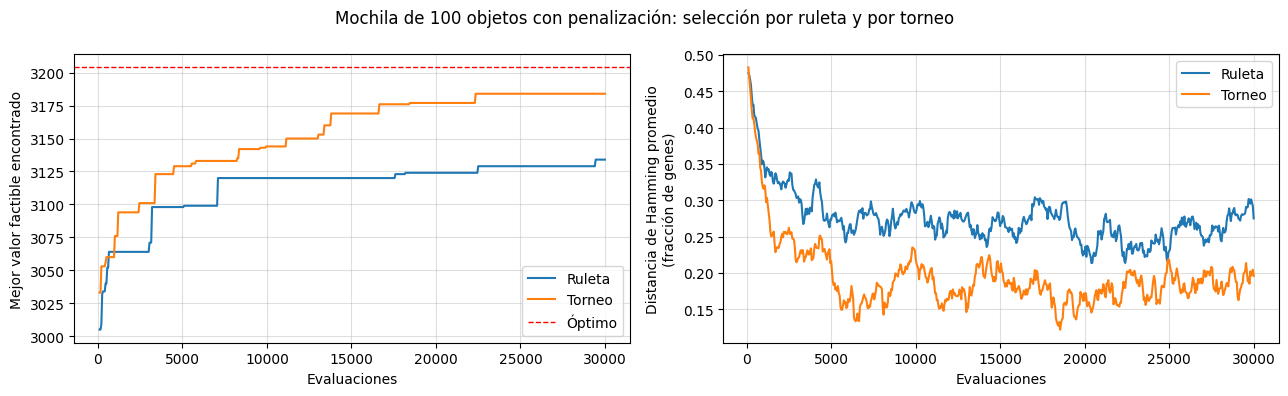

Ruleta : promedio  3139.8, mejor 3153 (5 semillas, 50 000 evaluaciones)


Torneo : promedio  3177.4, mejor 3184 (5 semillas, 50 000 evaluaciones)


In [7]:
historias = {}
for sel in ['ruleta', 'torneo']:
    random.seed(1)
    np.random.seed(1)
    cod = MochilaBinaria(pesos100, valores100, capacidad100, manejo='penalizacion', lam=0.5)
    mejor, hist = algoritmo_genetico(cod, Presupuesto(30000), seleccion=sel, medir_diversidad=True)
    historias[sel] = hist

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for sel, hist in historias.items():
    ejes[0].plot([h[0] for h in hist], [h[1] for h in hist], label=sel.capitalize())
    ejes[1].plot([h[0] for h in hist], [h[2] for h in hist], label=sel.capitalize())
ejes[0].axhline(OPTIMO_MOCHILA100, color='red', linestyle='--', linewidth=1, label='Óptimo')
ejes[0].set_ylabel('Mejor valor factible encontrado')
ejes[1].set_ylabel('Distancia de Hamming promedio\n(fracción de genes)')
for eje in ejes:
    eje.set_xlabel('Evaluaciones')
    eje.grid(True, alpha=0.4)
    eje.legend()
plt.suptitle('Mochila de 100 objetos con penalización: selección por ruleta y por torneo')
plt.tight_layout()
plt.show()

for sel in ['ruleta', 'torneo']:
    res = correr_ag(lambda: MochilaBinaria(pesos100, valores100, capacidad100, manejo='penalizacion', lam=0.5),
                    50000, semillas, seleccion=sel)
    print(f"{sel.capitalize():<7}: promedio {np.mean(res):7.1f}, mejor {max(res)} (5 semillas, 50 000 evaluaciones)")

Con el torneo, la diversidad baja más rápido y se queda cerca de 0,2, mientras que con la ruleta se queda cerca de 0,28, y el torneo encuentra mejores soluciones durante toda la corrida. Con 5 semillas, el torneo termina en 3177,4 en promedio y la ruleta en 3139,8. La presión de la ruleta depende de la escala de las aptitudes. La ruleta les resta a todas la menor de la población, y si esa aptitud está muy por debajo de las demás, como la de un individuo infactible muy penalizado, los individuos buenos quedan con probabilidades parecidas. El torneo solo compara qué individuo es mejor, sin importar por cuánto, y su presión no depende de la escala de la aptitud.

### Reemplazo

La tabla siguiente compara las cuatro variantes de reemplazo con penalización ($\lambda = 0{,}5$). La variante de reglas de factibilidad corresponde a una idea del laboratorio del curso, que compara dos individuos separando la factibilidad del valor. El hijo $i$ compite con el padre $i$ y gana el factible si solo uno lo es; si los dos lo son, gana el de mayor valor, y si ninguno lo es, el que viola menos la capacidad.

In [8]:
variantes = [
    ('Generacional sin elitismo', dict(reemplazo='generacional', elitismo=False)),
    ('Generacional con elitismo', dict(reemplazo='generacional', elitismo=True)),
    ('Competencia padres-hijos', dict(reemplazo='competencia')),
    ('Reglas de factibilidad', dict(reemplazo='restricciones')),
]
print("Mochila de 100 objetos con penalización (λ = 0,5), torneo, 50 000 evaluaciones, 5 semillas")
for nombre, opciones in variantes:
    res = correr_ag(lambda: MochilaBinaria(pesos100, valores100, capacidad100, manejo='penalizacion', lam=0.5),
                    50000, semillas, **opciones)
    print(f"  {nombre:<26}: promedio {np.mean(res):7.1f}, mejor {max(res)}, peor {min(res)}")

Mochila de 100 objetos con penalización (λ = 0,5), torneo, 50 000 evaluaciones, 5 semillas


  Generacional sin elitismo : promedio  3126.6, mejor 3141, peor 3112


  Generacional con elitismo : promedio  3177.4, mejor 3184, peor 3164


  Competencia padres-hijos  : promedio  3139.0, mejor 3161, peor 3114


  Reglas de factibilidad    : promedio  3166.0, mejor 3174, peor 3154


El elitismo es la diferencia más grande. Sin él, el reemplazo generacional termina en 3126,6 en promedio, porque el mejor individuo se puede perder de una generación a la siguiente; con él, en 3177,4. La competencia entre padres e hijos termina en 3139,0, y las reglas de factibilidad, en 3166,0. Ninguna de las dos supera al generacional con elitismo en esta instancia, aunque las dos conservan en parte a los padres buenos.

## Permutaciones: el agente viajero y las reinas

En el agente viajero y en las reinas, un individuo es una permutación, y los operadores binarios no sirven, porque cruzar o mutar gen por gen produce listas con ciudades repetidas o ausentes. Los operadores de permutaciones de la celda siguiente producen siempre permutaciones:

- el cruce de orden (*order crossover*, OX) copia en el hijo un tramo del primer padre, en las mismas posiciones, y llena las posiciones restantes con las ciudades que faltan, en el orden en que aparecen en el segundo padre;
- el cruce parcialmente emparejado (*partially mapped crossover*, PMX) copia también un tramo del primer padre y toma las demás posiciones del segundo, y cuando una ciudad del segundo padre ya está en el tramo, usa la correspondencia entre los dos tramos para ubicarla en otra posición;
- la mutación por intercambio permuta dos posiciones, la de inserción saca un elemento y lo pone en otra posición, y la de inversión invierte el orden de un tramo, que en el agente viajero es el movimiento 2-opt.

La clase `Permutacion` aplica la mutación a cada hijo con probabilidad 0,3. La celda comprueba que OX y PMX producen permutaciones válidas y después compara las seis combinaciones de cruce y mutación en el agente viajero, con 50 000 evaluaciones, y las tres mutaciones con PMX en las reinas, con 20 000.

In [9]:
def cruce_ox(p1, p2):
    """Cruce de orden (OX): copia un tramo del primer padre y completa con el orden del segundo."""
    n = len(p1)
    i, j = sorted(random.sample(range(n), 2))
    def hijo(a, b):
        tramo = a[i:j + 1]
        en_tramo = set(tramo)
        resto = [c for c in b[j + 1:] + b[:j + 1] if c not in en_tramo]
        h = [None] * n
        h[i:j + 1] = tramo
        posiciones = list(range(j + 1, n)) + list(range(0, i))
        for pos, c in zip(posiciones, resto):
            h[pos] = c
        return h
    return hijo(p1, p2), hijo(p2, p1)


def cruce_pmx(p1, p2):
    """Cruce parcialmente emparejado (PMX): copia un tramo y resuelve los repetidos con la correspondencia del tramo."""
    n = len(p1)
    i, j = sorted(random.sample(range(n), 2))
    def hijo(a, b):
        h = [None] * n
        h[i:j + 1] = a[i:j + 1]
        posicion_en_b = {c: k for k, c in enumerate(b)}
        for k in range(i, j + 1):
            c = b[k]
            if c in h[i:j + 1]:
                continue
            pos = k
            while i <= pos <= j:
                pos = posicion_en_b[a[pos]]
            h[pos] = c
        for k in range(n):
            if h[k] is None:
                h[k] = b[k]
        return h
    return hijo(p1, p2), hijo(p2, p1)


def mutacion_intercambio(s):
    t = list(s)
    i, j = random.sample(range(len(t)), 2)
    t[i], t[j] = t[j], t[i]
    return t


def mutacion_insercion(s):
    t = list(s)
    c = t.pop(random.randrange(len(t)))
    t.insert(random.randrange(len(t) + 1), c)
    return t


def mutacion_inversion(s):
    t = list(s)
    i, j = sorted(random.sample(range(len(t)), 2))
    t[i:j + 1] = t[i:j + 1][::-1]
    return t


class Permutacion:
    """Codificación por permutaciones para el agente viajero o las reinas."""

    def __init__(self, costo, n, cruce, mutacion, prob_mutacion=0.3):
        self.costo, self.n = costo, n
        self.op_cruce, self.op_mutacion, self.pm = cruce, mutacion, prob_mutacion

    def aleatoria(self):
        return list(np.random.permutation(self.n))

    def copiar(self, x):
        return list(x)

    def diversidad(self, poblacion):
        """Fracción promedio de posiciones distintas entre pares de individuos."""
        X = np.array([ind.x for ind in poblacion])
        m = len(X)
        dist = [(X[a] != X[b]).mean() for a in range(m) for b in range(a + 1, m)]
        return float(np.mean(dist))

    def evaluar(self, x):
        valor = -self.costo(x)
        return Individuo(x, valor, 0, valor)

    def cruce(self, x, y):
        return self.op_cruce(x, y)

    def mutacion(self, x):
        return self.op_mutacion(x) if random.random() < self.pm else x


# Comprobación: los operadores producen permutaciones válidas
random.seed(0)
for _ in range(500):
    a, b = list(np.random.permutation(12)), list(np.random.permutation(12))
    for h in cruce_ox(a, b) + cruce_pmx(a, b):
        assert sorted(h) == list(range(12))
print("OX y PMX producen permutaciones válidas en 500 cruces al azar")

OX y PMX producen permutaciones válidas en 500 cruces al azar


In [10]:
combinaciones = [('OX', cruce_ox), ('PMX', cruce_pmx)]
mutaciones = [('intercambio', mutacion_intercambio), ('inserción', mutacion_insercion), ('inversión', mutacion_inversion)]
print("Viajero, 50 ciudades, 50 000 evaluaciones, torneo, generacional con elitismo, 5 semillas")
for nc, cr in combinaciones:
    for nm, mu in mutaciones:
        inicio = time.perf_counter()
        res = correr_ag(lambda: Permutacion(viajero.costo, N_CIUDADES, cr, mu), 50000, semillas)
        print(f"  {nc} + {nm:<11}: promedio {-np.mean(res):7.2f}, mejor {-max(res):7.2f} ({time.perf_counter() - inicio:.1f} s)")

print("\nReinas de 30 x 30, 20 000 evaluaciones, PMX, 5 semillas")
for nm, mu in mutaciones:
    res = correr_ag(lambda: Permutacion(reinas.costo, 30, cruce_pmx, mu), 20000, semillas)
    print(f"  PMX + {nm:<11}: conflictos promedio {-np.mean(res):.2f}, sin conflictos en {sum(r == 0 for r in res)} de 5")

Viajero, 50 ciudades, 50 000 evaluaciones, torneo, generacional con elitismo, 5 semillas


  OX + intercambio: promedio  851.01, mejor  828.30 (3.3 s)


  OX + inserción  : promedio  812.66, mejor  718.91 (3.3 s)


  OX + inversión  : promedio  882.38, mejor  866.51 (3.3 s)


  PMX + intercambio: promedio  763.18, mejor  696.54 (4.0 s)


  PMX + inserción  : promedio  735.02, mejor  688.53 (4.0 s)


  PMX + inversión  : promedio  599.97, mejor  575.64 (4.2 s)

Reinas de 30 x 30, 20 000 evaluaciones, PMX, 5 semillas


  PMX + intercambio: conflictos promedio 0.40, sin conflictos en 3 de 5


  PMX + inserción  : conflictos promedio 0.80, sin conflictos en 1 de 5


  PMX + inversión  : conflictos promedio 1.00, sin conflictos en 1 de 5


En el agente viajero, la combinación de PMX con inversión es claramente la mejor, con 599,97 en promedio. Las otras cinco combinaciones quedan entre 735,02 y 882,38, lejos de los óptimos locales de 2-opt del capítulo 3. La inversión cambia solo dos arcos del recorrido, mientras que el intercambio y la inserción cambian hasta cuatro y tres, y en esta instancia es la única mutación que ayuda. Con OX, en cambio, la inversión es la peor de las tres mutaciones, de modo que el efecto de un operador depende de con cuál se combina. En las reinas, PMX con intercambio llega a cero conflictos en 3 de las 5 semillas, y con inserción o inversión, en 1.

## Tamaño de la población

Con un presupuesto fijo de evaluaciones, el tamaño de la población reparte el presupuesto entre explorar y avanzar. Una población grande mantiene más diversidad, pero hace menos generaciones; con 50 000 evaluaciones, una población de 200 hace 250 generaciones y una de 20 hace 2500. La celda siguiente prueba cuatro tamaños en el agente viajero, con PMX e inversión, y en la mochila con penalización.

In [11]:
print("Viajero, 50 ciudades, 50 000 evaluaciones, PMX + inversión, 5 semillas")
for tam in [20, 50, 100, 200]:
    res = correr_ag(lambda: Permutacion(viajero.costo, N_CIUDADES, cruce_pmx, mutacion_inversion), 50000, semillas,
                    tam_poblacion=tam)
    print(f"  población {tam:>3}: promedio {-np.mean(res):7.2f}, mejor {-max(res):7.2f}")
print("\nMochila de 100 objetos con penalización (λ = 0,5), 50 000 evaluaciones, 5 semillas")
for tam in [20, 50, 100, 200]:
    res = correr_ag(lambda: MochilaBinaria(pesos100, valores100, capacidad100, manejo='penalizacion', lam=0.5),
                    50000, semillas, tam_poblacion=tam)
    print(f"  población {tam:>3}: promedio {np.mean(res):7.1f}, mejor {max(res)}")

Viajero, 50 ciudades, 50 000 evaluaciones, PMX + inversión, 5 semillas


  población  20: promedio  599.29, mejor  583.81


  población  50: promedio  599.97, mejor  575.64


  población 100: promedio  805.56, mejor  693.20


  población 200: promedio 1300.09, mejor 1236.46

Mochila de 100 objetos con penalización (λ = 0,5), 50 000 evaluaciones, 5 semillas


  población  20: promedio  3183.8, mejor 3194


  población  50: promedio  3177.4, mejor 3184


  población 100: promedio  3164.8, mejor 3180


  población 200: promedio  3156.4, mejor 3164


En los dos problemas, las poblaciones pequeñas dan mejores resultados con este presupuesto. En el agente viajero, las poblaciones de 20 y de 50 terminan cerca de 600 en promedio, la de 100 en 805,56 y la de 200 en 1300,09, porque con tan pocas generaciones la población grande no alcanza a converger. En la mochila la diferencia es menor, de 3183,8 con 20 individuos a 3156,4 con 200. Con más presupuesto, el tamaño adecuado sería mayor, y una población muy pequeña corre el riesgo de perder diversidad y converger a una solución mediocre.

## Comparación con los métodos de trayectoria

La celda siguiente compara el algoritmo genético con ILS, la búsqueda tabú y la GVNS de los capítulos 4 a 6, con 10 semillas y los presupuestos de esos capítulos. El algoritmo genético usa la mejor configuración de las tablas anteriores para cada problema, que son la reparación en la mochila, PMX con intercambio en las reinas y PMX con inversión y una población de 20 en el agente viajero. Como esas configuraciones se escogieron sobre las mismas instancias, la comparación favorece al algoritmo genético.

In [12]:
metodos = {
    'AG': None,
    'ILS': lambda prob, pres: busqueda_local_iterada(prob, pres),
    'Tabú': None,
    'GVNS': None,
}
num_semillas = 10
configuracion = {
    'Mochila (100 objetos)': dict(
        prob=mochila100, max_eval=100000,
        ag=lambda: MochilaBinaria(pesos100, valores100, capacidad100, manejo='reparacion'), ag_tam=50,
        tabu=dict(permanencia=20, muestra=200),
        gvns=lambda: gvns(mochila100, PRES, agitar_mochila, [Flip(mochila100), Intercambio(mochila100), Intercambio12(mochila100)])),
    'Reinas (30 x 30)': dict(
        prob=reinas, max_eval=20000,
        ag=lambda: Permutacion(reinas.costo, 30, cruce_pmx, mutacion_intercambio), ag_tam=50,
        tabu=dict(permanencia=10, muestra=100), gvns=None),
    'Viajero (50 ciudades)': dict(
        prob=viajero, max_eval=200000,
        ag=lambda: Permutacion(viajero.costo, N_CIUDADES, cruce_pmx, mutacion_inversion), ag_tam=20,
        tabu=dict(permanencia=20, muestra=None),
        gvns=lambda: gvns(viajero, PRES, agitar_viajero, [DosOpt(viajero), OrOpt(viajero)])),
}
resultados = {}
for nombre_prob, cfg in configuracion.items():
    prob, max_eval = cfg['prob'], cfg['max_eval']
    for nombre_met in metodos:
        if nombre_met == 'GVNS' and cfg['gvns'] is None:
            continue
        costos = []
        inicio = time.perf_counter()
        for semilla in range(num_semillas):
            random.seed(semilla)
            np.random.seed(semilla)
            PRES = Presupuesto(max_eval)
            if nombre_met == 'AG':
                mejor, _ = algoritmo_genetico(cfg['ag'](), PRES, tam_poblacion=cfg['ag_tam'])
                costos.append(-mejor.valor)
            elif nombre_met == 'ILS':
                costos.append(busqueda_local_iterada(prob, PRES)[1])
            elif nombre_met == 'Tabú':
                costos.append(busqueda_tabu(prob, PRES, **cfg['tabu'])[1])
            else:
                costos.append(cfg['gvns']()[1])
        resultados[(nombre_prob, nombre_met)] = (costos, time.perf_counter() - inicio)

for nombre_prob, cfg in configuracion.items():
    signo = -1 if nombre_prob.startswith('Mochila') else 1
    print(f"{nombre_prob}, presupuesto de {cfg['max_eval']:,d} evaluaciones, {num_semillas} semillas")
    print(f"  {'método':<6} | {'promedio':>9} | {'mejor':>8} | {'peor':>8} | {'tiempo':>7}")
    for nombre_met in metodos:
        if (nombre_prob, nombre_met) not in resultados:
            continue
        costos, t = resultados[(nombre_prob, nombre_met)]
        v = [signo * c for c in costos]
        mejor, peor = (max(v), min(v)) if signo < 0 else (min(v), max(v))
        print(f"  {nombre_met:<6} | {np.mean(v):>9.2f} | {mejor:>8.2f} | {peor:>8.2f} | {t:>6.1f}s")
    print()

Mochila (100 objetos), presupuesto de 100,000 evaluaciones, 10 semillas
  método |  promedio |    mejor |     peor |  tiempo
  AG     |   3204.00 |  3204.00 |  3204.00 |   17.8s
  ILS    |   3023.00 |  3064.00 |  2984.00 |    2.3s
  Tabú   |   3016.00 |  3044.00 |  2984.00 |    3.8s
  GVNS   |   3196.00 |  3204.00 |  3194.00 |    3.4s

Reinas (30 x 30), presupuesto de 20,000 evaluaciones, 10 semillas
  método |  promedio |    mejor |     peor |  tiempo
  AG     |      0.30 |     0.00 |     1.00 |    2.9s
  ILS    |      0.00 |     0.00 |     0.00 |    2.9s
  Tabú   |      0.00 |     0.00 |     0.00 |    3.0s

Viajero (50 ciudades), presupuesto de 200,000 evaluaciones, 10 semillas
  método |  promedio |    mejor |     peor |  tiempo
  AG     |    591.00 |   565.54 |   633.57 |   32.4s
  ILS    |    559.06 |   556.20 |   566.77 |    3.4s
  Tabú   |    567.56 |   556.20 |   586.44 |    2.8s
  GVNS   |    562.41 |   556.84 |   570.48 |    3.0s



En la mochila, el algoritmo genético con reparación llega al óptimo en las 10 semillas, y la GVNS en 2. Como se vio arriba, buena parte de ese resultado se debe a la reparación voraz. En las reinas, el algoritmo genético llega a cero conflictos en 7 de las 10 semillas, mientras que ILS y la búsqueda tabú lo logran en todas. En el agente viajero queda lejos de los métodos de trayectoria, con 591,00 en promedio frente a 559,06 de ILS, y además tarda unas diez veces más. Sin búsqueda local, el algoritmo genético mejora los recorridos solo a través del cruce y de la mutación, sin explotar de forma sistemática el vecindario de cada solución. Los algoritmos meméticos del capítulo 13 combinan las dos cosas, un algoritmo genético cuyos hijos pasan por una búsqueda local.